In [15]:
# 📦 Imports
import pandas as pd
import numpy as np
import time
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 📂 Load dataset
file_path = r'F:\Program Files (x86)\OneDrive\Desktop\ML edit 18\Cryogenic\Cryogenic_Temp_3x_Augmented_1Percent_Noise.xlsx'
df = pd.read_excel(file_path)

# 🧹 Features and Target
X = df.drop(columns=["Composite TC"])
y = df["Composite TC"]

# ✂️ Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ✅ Plugged-in Best Hyperparameters from RandomizedSearchCV
xgb_model = XGBRegressor(
    subsample=0.5,
    reg_lambda=5,
    reg_alpha=0.1,
    n_estimators=250,
    max_depth=3,
    learning_rate=0.03,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=0,
    n_jobs=-1
)

# 🚀 Train the model
start = time.time()
xgb_model.fit(X_train, y_train)
end = time.time()

# 📈 Predictions
y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)

# 📊 Evaluation Function
def print_metrics(true, pred, dataset_name="Dataset"):
    print(f"\n{dataset_name} Metrics:")
    print(f"MAE:  {mean_absolute_error(true, pred):.4f}")
    print(f"RMSE: {mean_squared_error(true, pred, squared=False):.4f}")
    print(f"R²:   {r2_score(true, pred):.4f}")

# 🧾 Final Evaluation
print_metrics(y_train, y_train_pred, "Train")
print_metrics(y_test, y_test_pred, "Test")

# 🔁 5-Fold Cross-validation
cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=5, scoring='r2', n_jobs=-1)
print(f"\n📉 5-Fold Cross-Validation R² Scores: {np.round(cv_scores, 4)}")
print(f"Mean CV R²: {cv_scores.mean():.4f}")
print(f"Std Dev CV R²: {cv_scores.std():.4f}")

print(f"\n⏱ Training Time: {end - start:.2f} seconds")



Train Metrics:
MAE:  0.0392
RMSE: 0.0530
R²:   0.9574

Test Metrics:
MAE:  0.0547
RMSE: 0.0663
R²:   0.9304

📉 5-Fold Cross-Validation R² Scores: [0.7822 0.8113 0.8897 0.9114 0.8892]
Mean CV R²: 0.8567
Std Dev CV R²: 0.0505

⏱ Training Time: 0.10 seconds



⏱ Training Time: 0.24 seconds

Train Metrics:
MAE:  0.0392
RMSE: 0.0530
R²:   0.9574

Test Metrics:
MAE:  0.0547
RMSE: 0.0663
R²:   0.9304

📉 5-Fold Cross-Validation R² Scores: [0.9257 0.8515 0.7803 0.8548 0.9226]
Mean CV R²: 0.8670
Std Dev CV R²: 0.0537

🔍 Full Test Data (20% sample):
       Base TC     Filler TC        Vol        Temp  Composite_Tc
158  0.196109     30.141845  30.028820   89.685620      0.903681
109  0.049104   2511.298205   6.948666    3.940242      0.081549
131  0.020108   1198.025794  19.872277   20.191215      0.447243
55   0.051119   2453.490408   6.977799    3.984166      0.080704
94   0.202079     30.156872  25.544664   79.202469      0.713021
29   0.020000   1200.000000  25.000000   20.000000      0.550000
101  0.200313     30.089364  30.345538   77.515145      0.846113
51   0.200000     30.000000  30.000000  100.000000      0.920000
100  0.378163  23904.402361  20.003195    7.043156      0.805426
144  0.020263   1196.953035  30.036207   19.788426      0.651

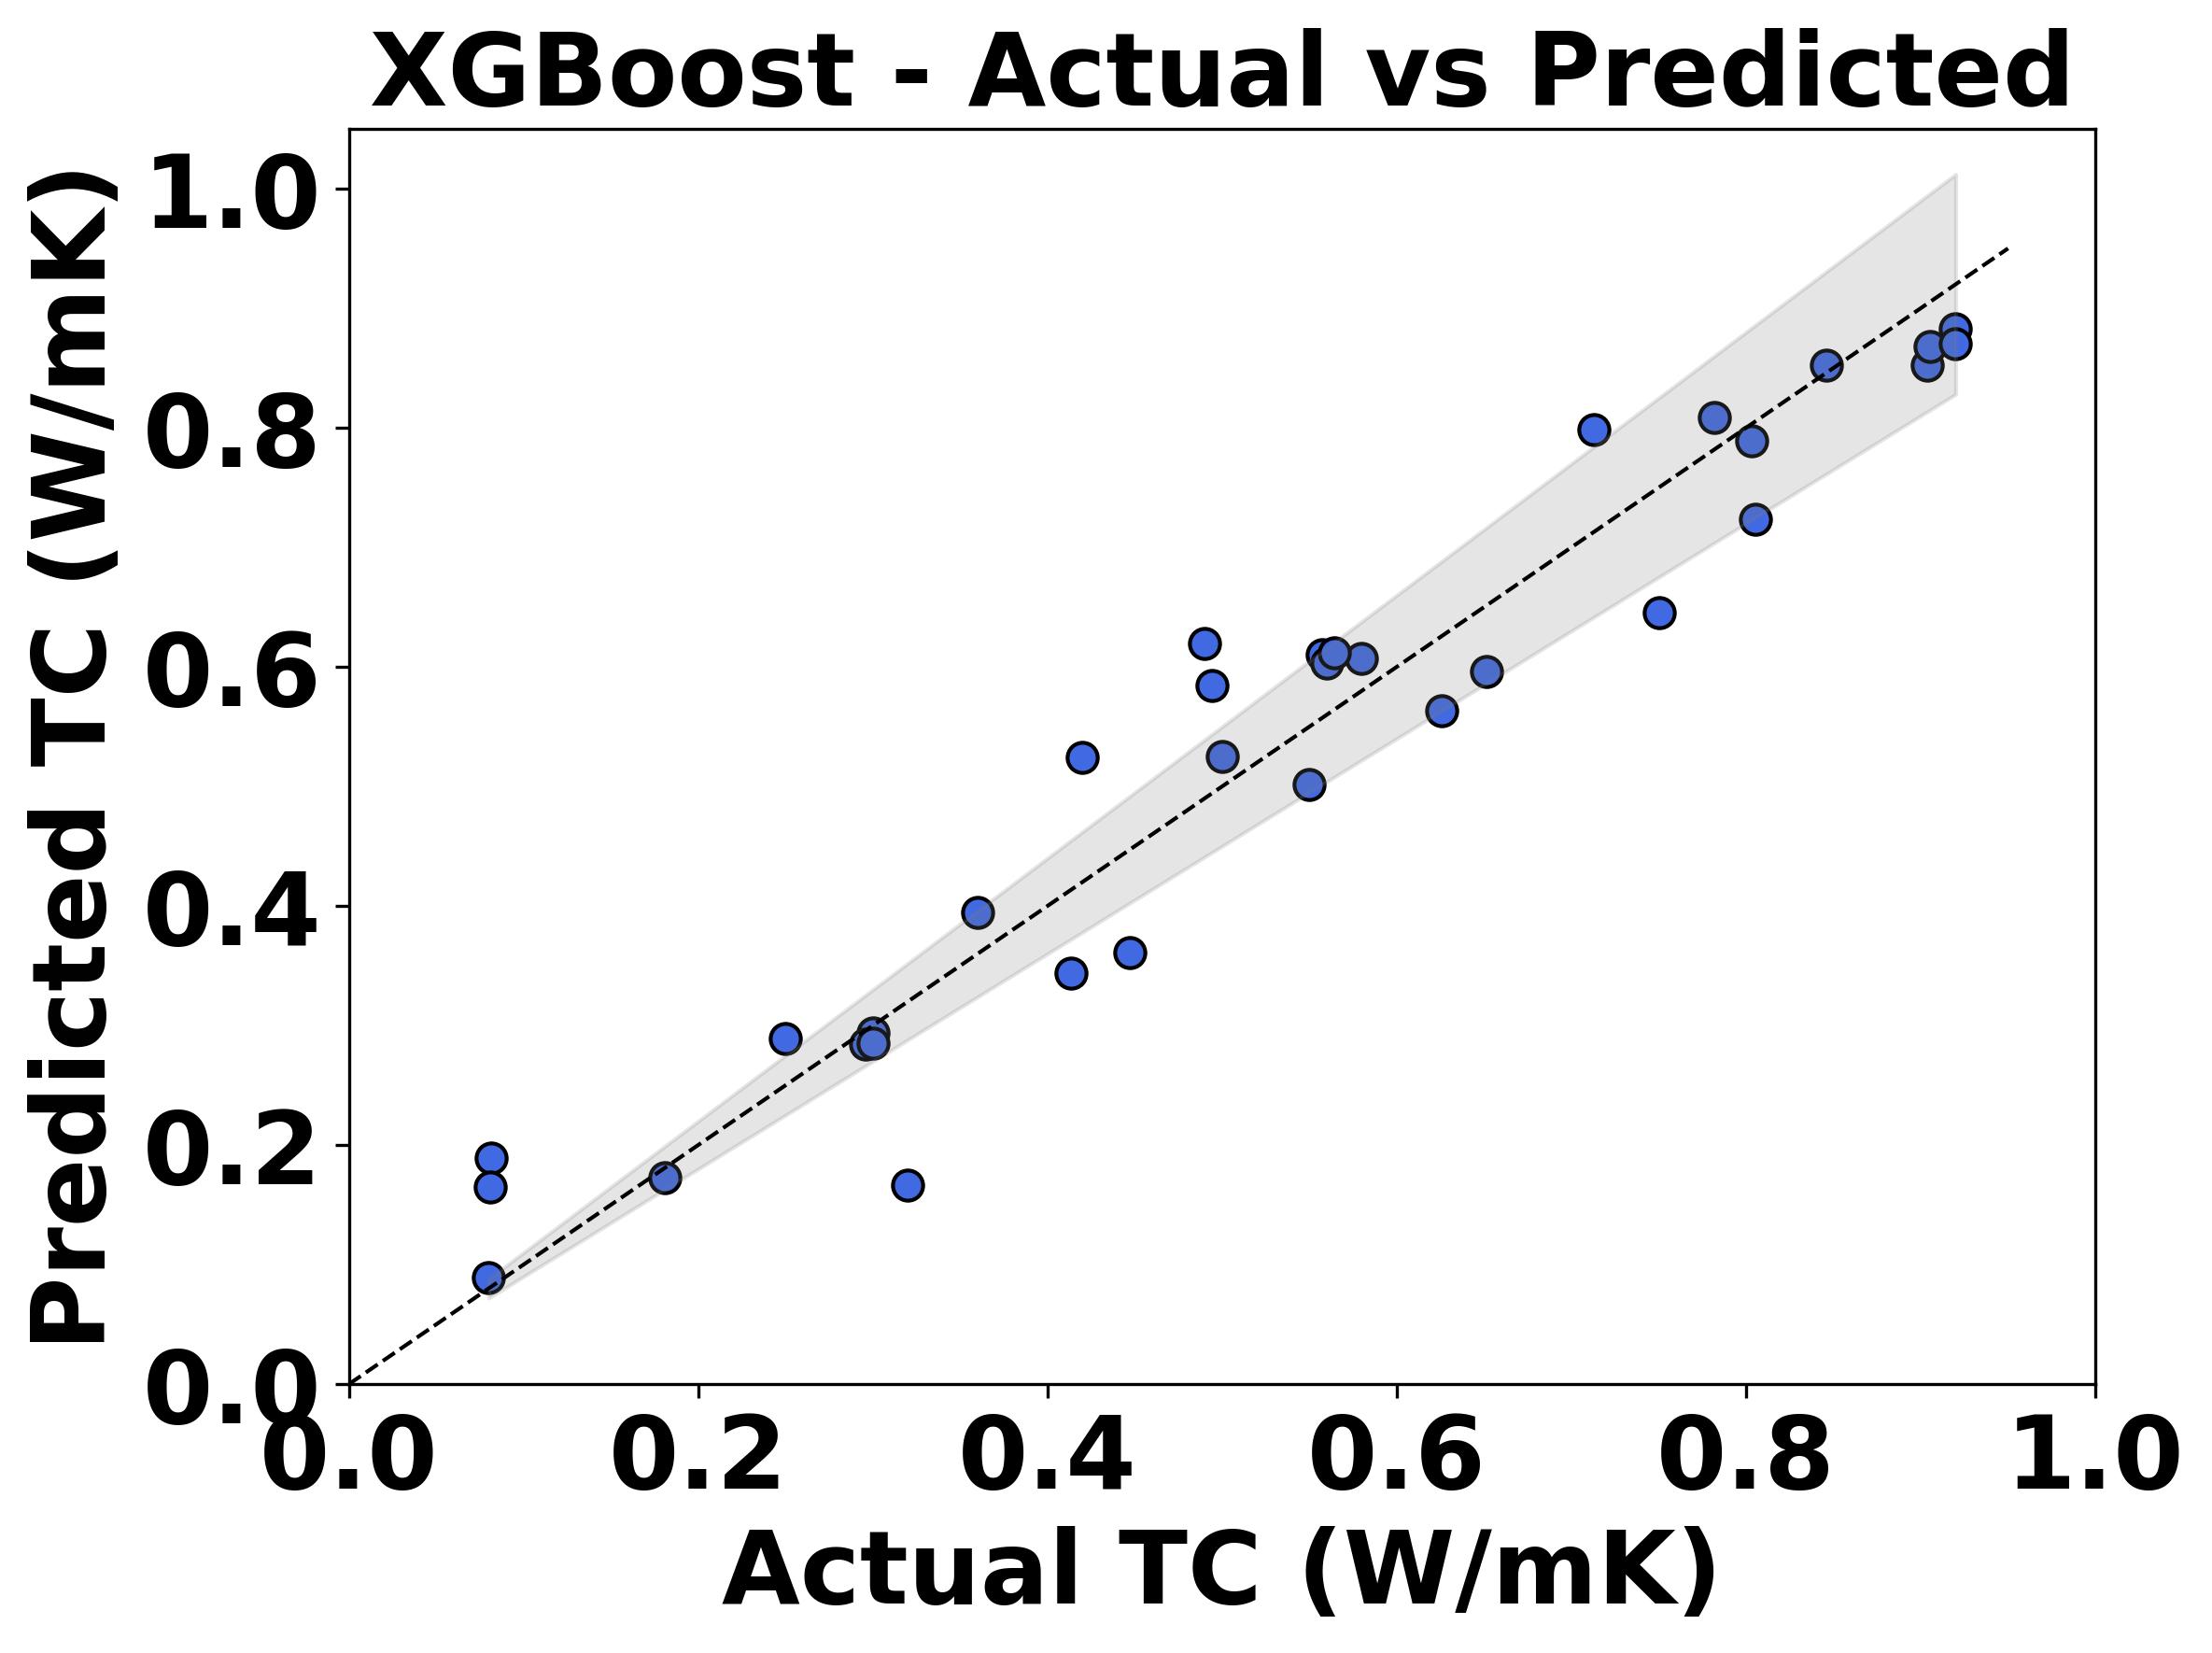

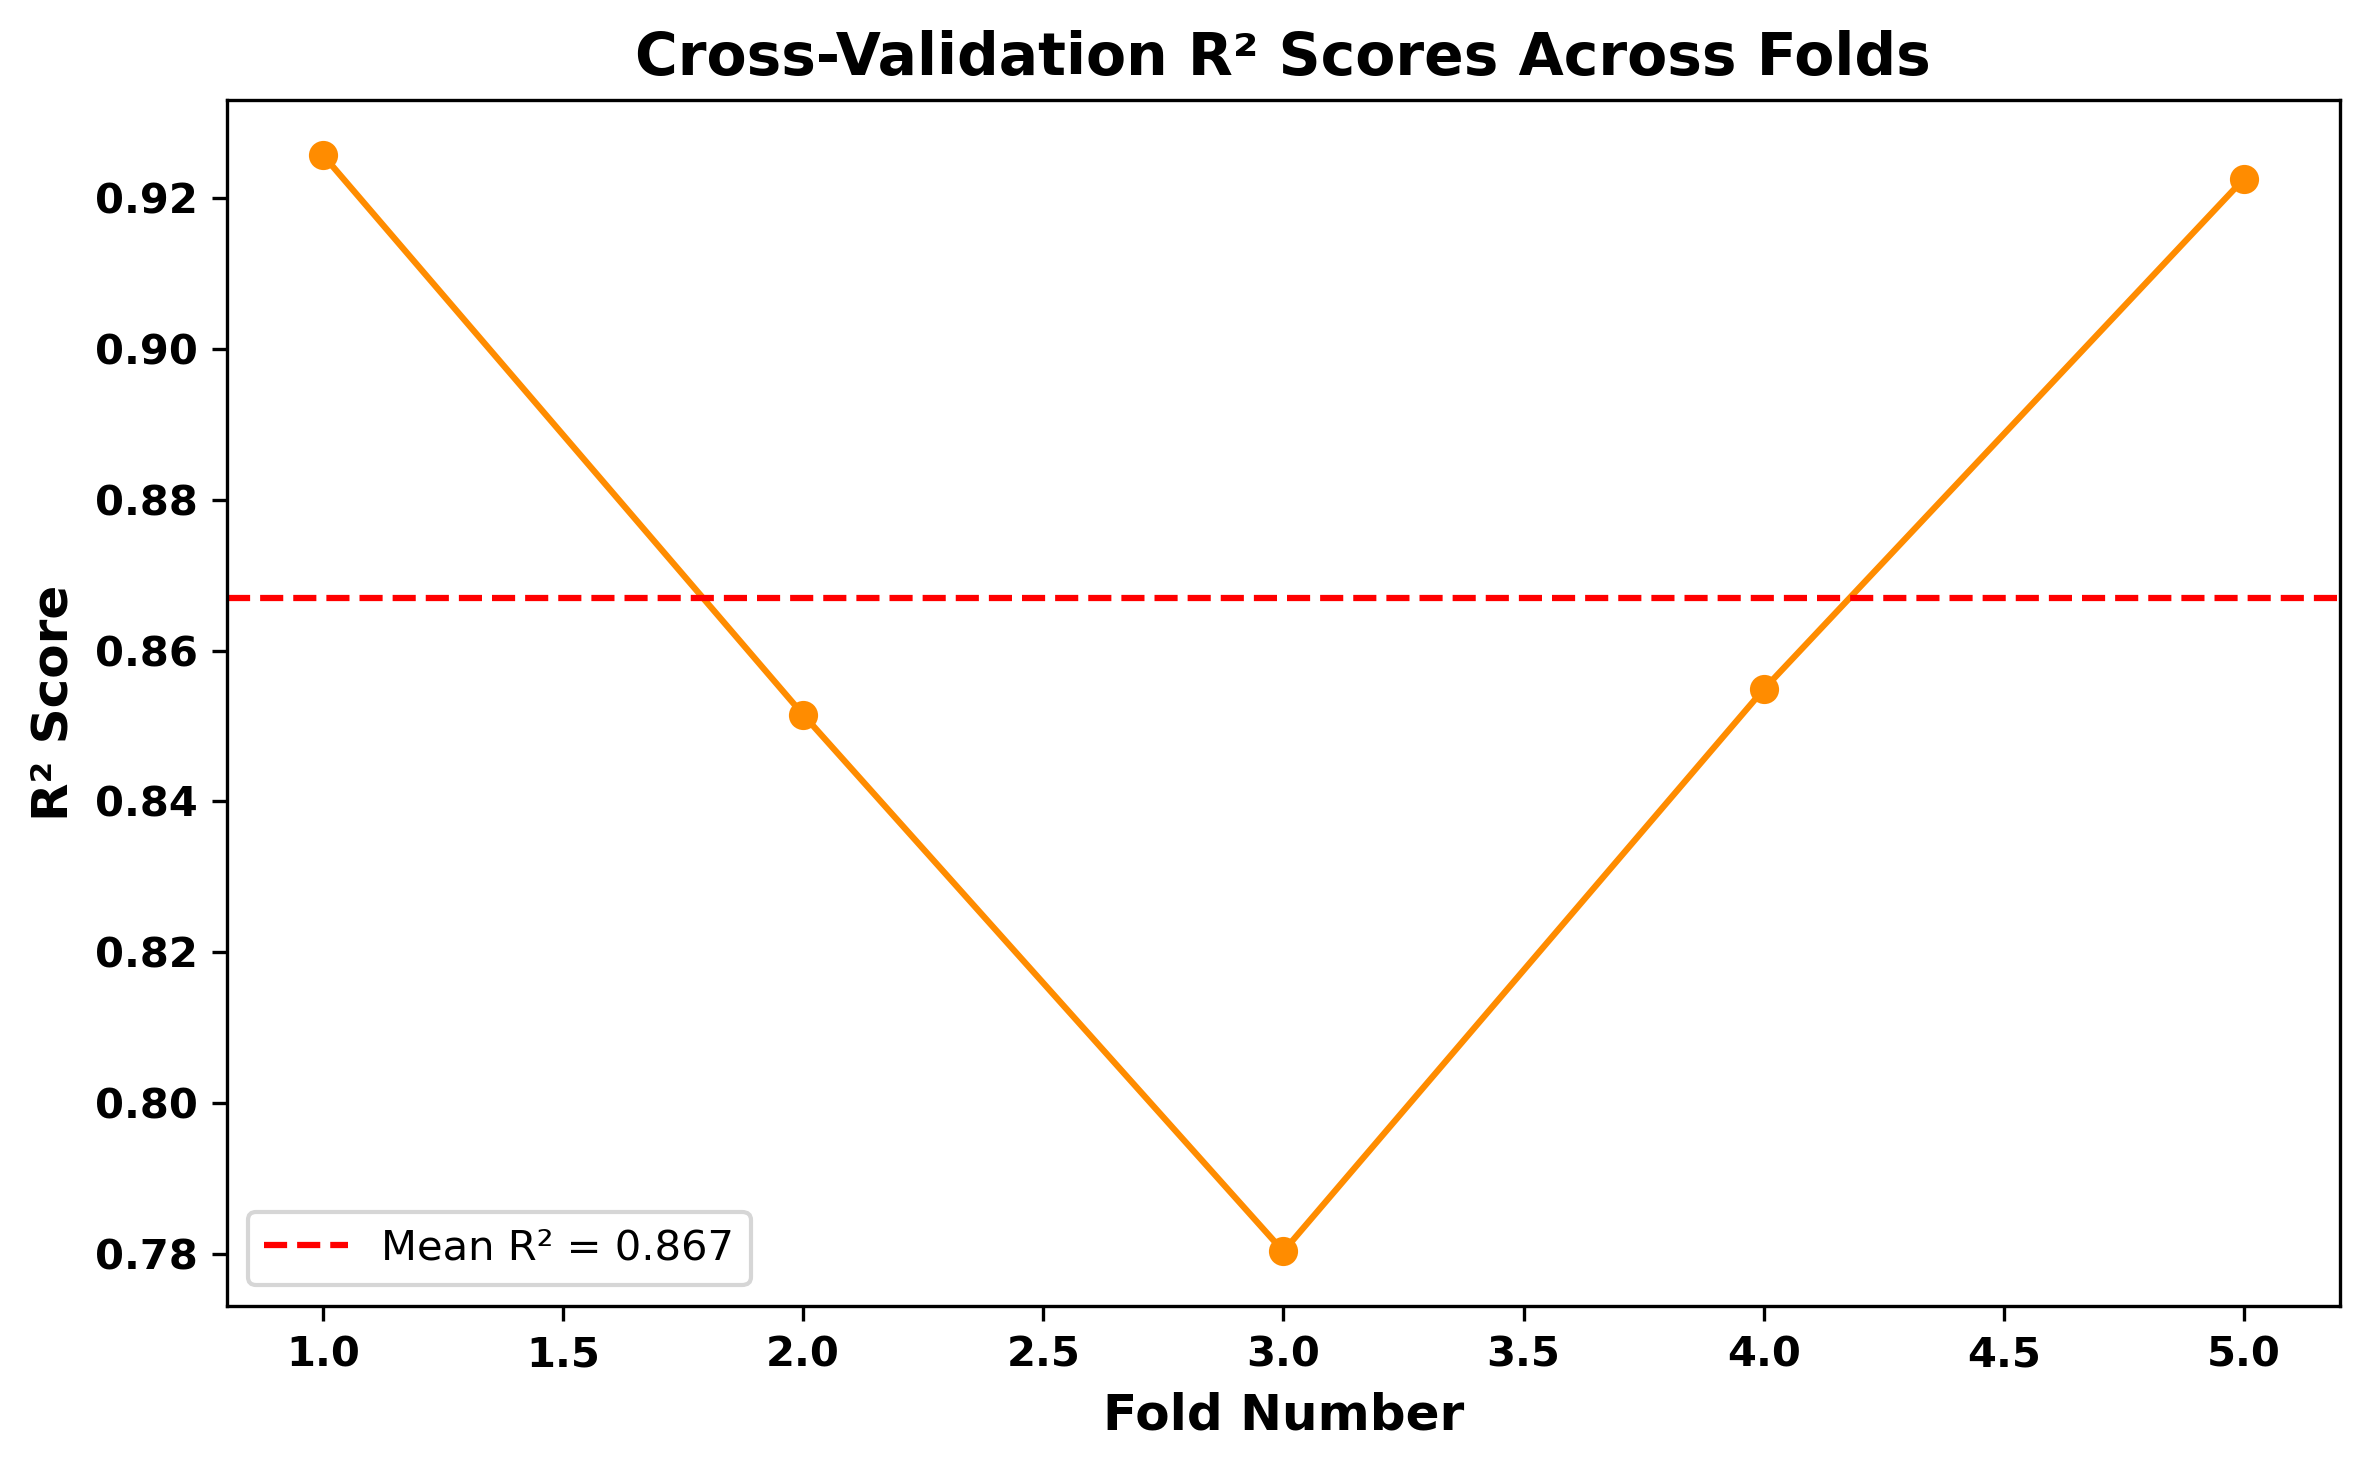

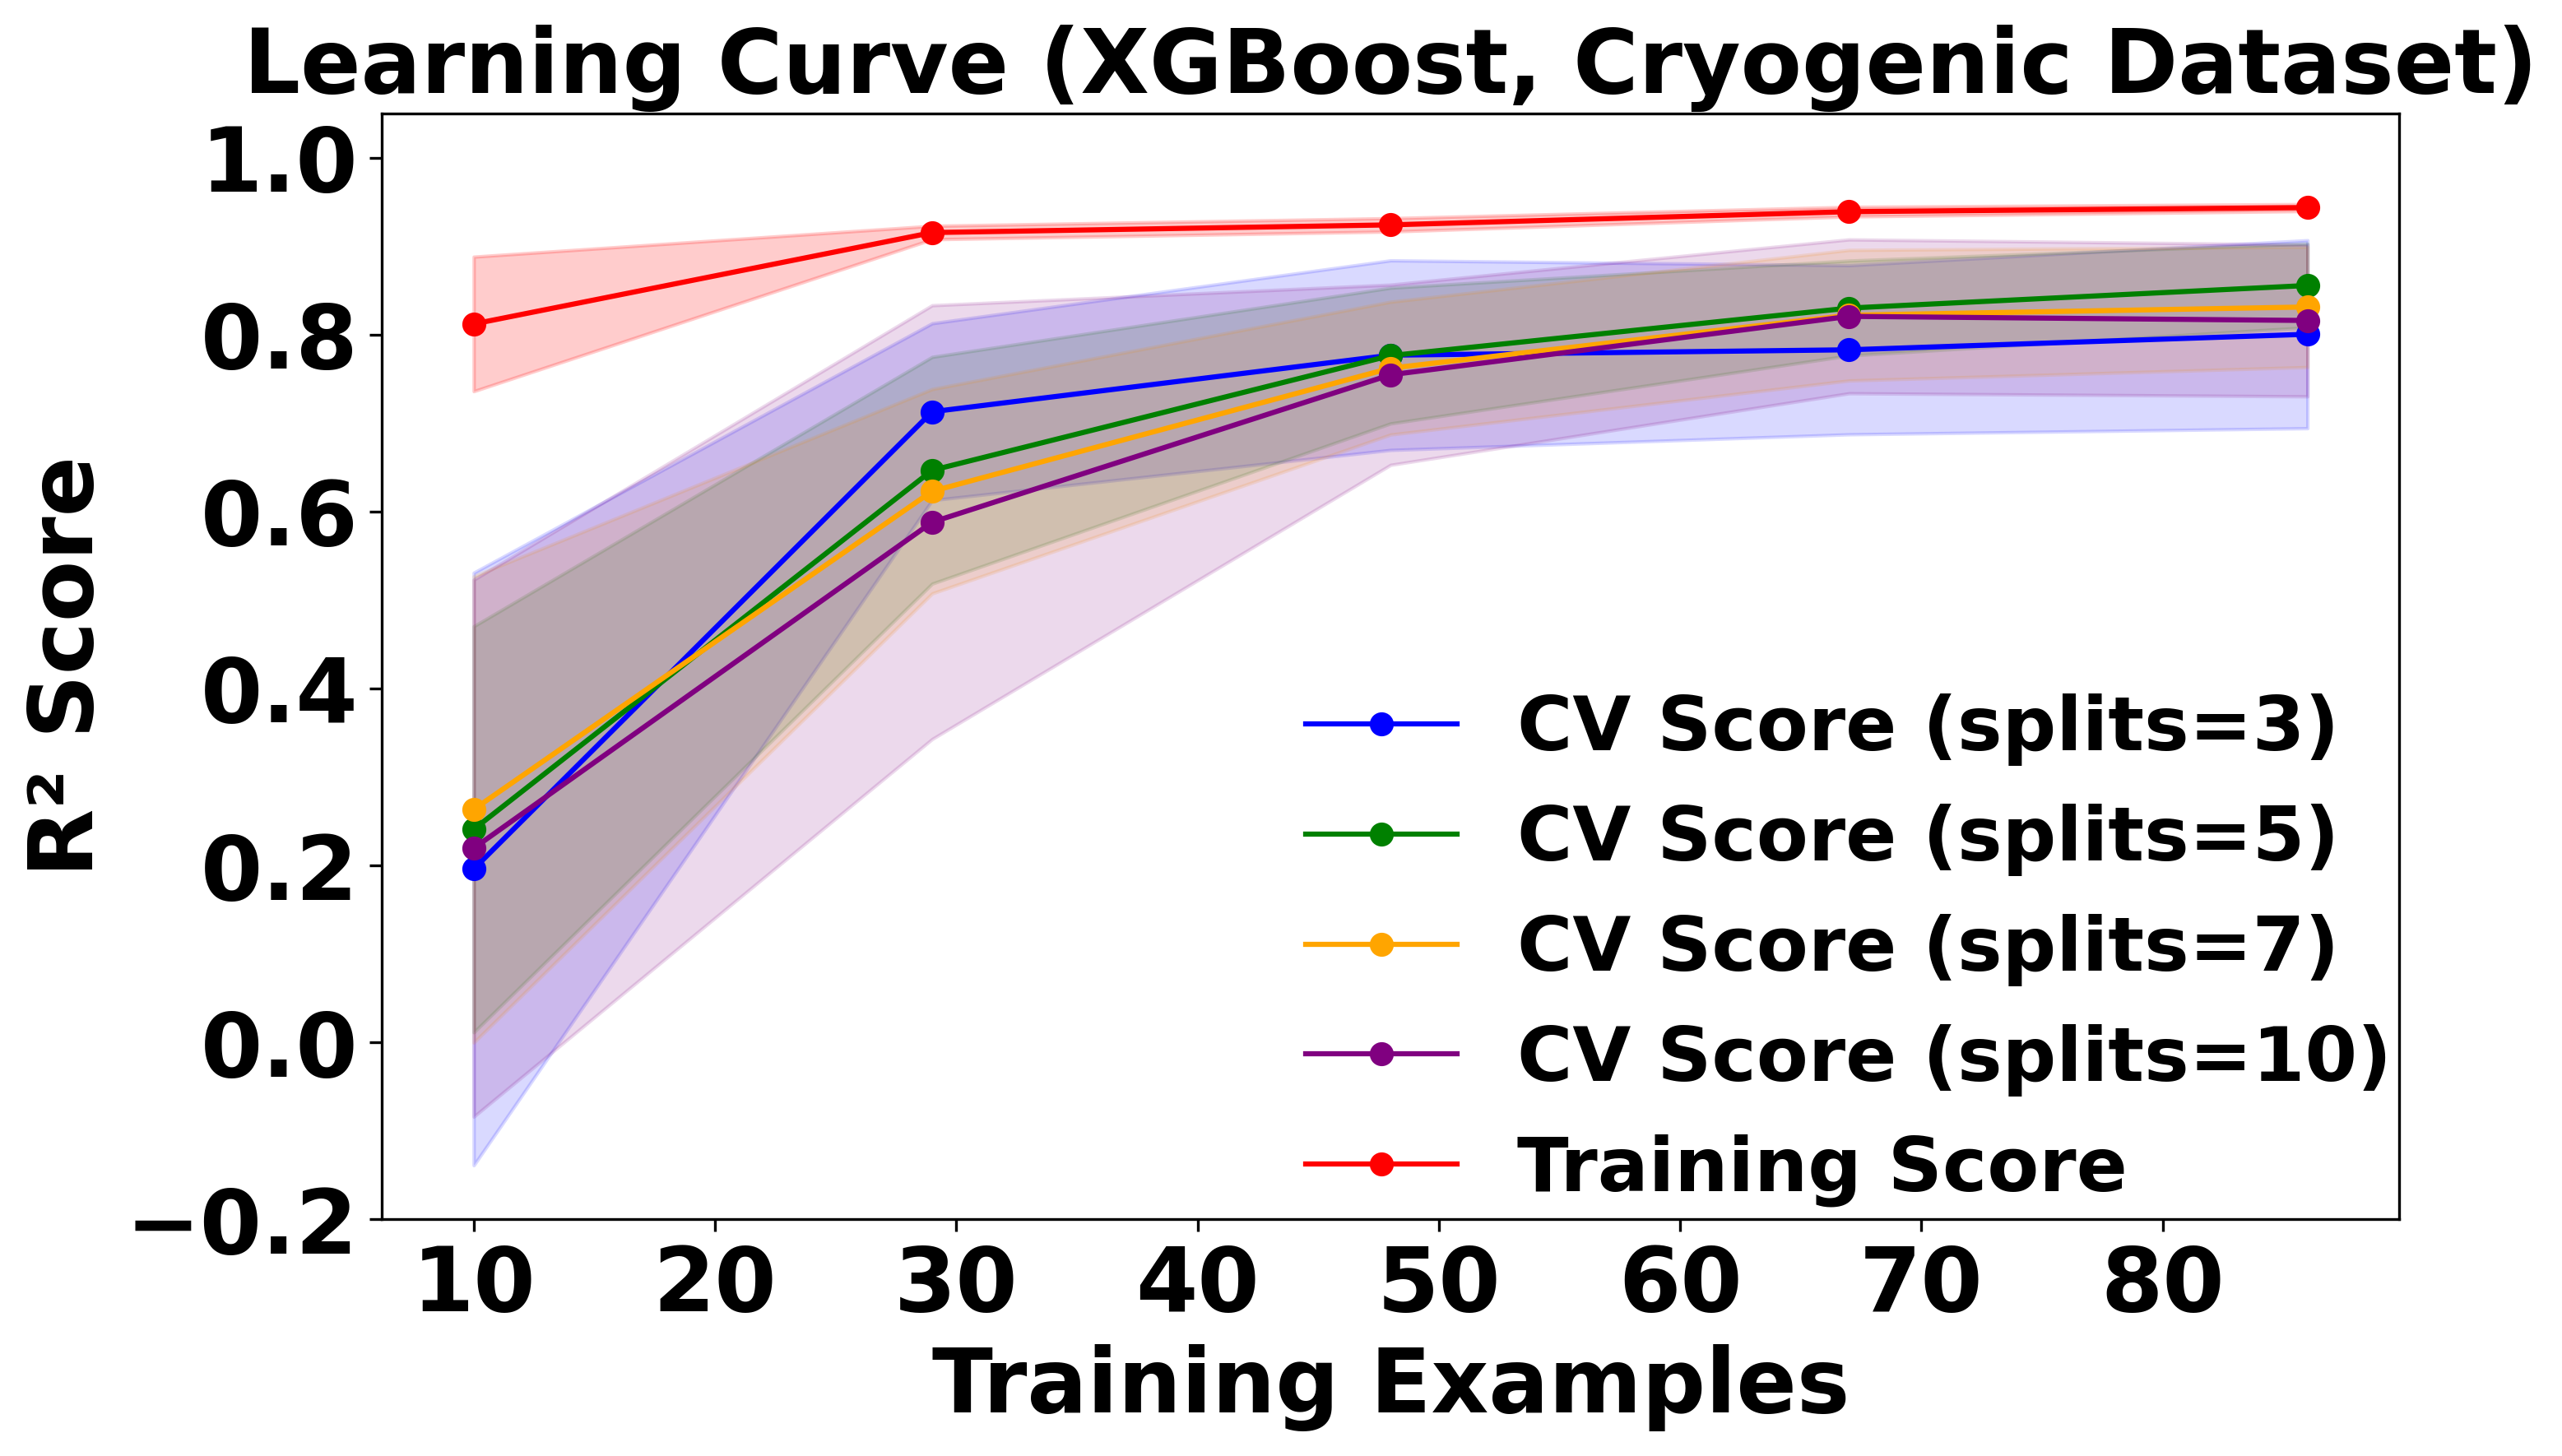

In [21]:
# 📦 Imports
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, KFold, learning_curve
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 📂 Load dataset
file_path = r'F:\Program Files (x86)\OneDrive\Desktop\ML edit 18\Cryogenic\Cryogenic_Temp_3x_Augmented_1Percent_Noise.xlsx'
df = pd.read_excel(file_path)

# 🧹 Features and Target
X = df.drop(columns=["Composite TC"])
y = df["Composite TC"]

# ✂️ Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ✅ Final XGBoost model with tuned hyperparameters
xgb_model = XGBRegressor(
    subsample=0.5,
    reg_lambda=5,
    reg_alpha=0.1,
    n_estimators=250,
    max_depth=3,
    learning_rate=0.03,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=0,
    n_jobs=-1
)

# 🚀 Train Model
start = time.time()
xgb_model.fit(X_train, y_train)
end = time.time()
print(f"\n⏱ Training Time: {end - start:.2f} seconds")

# 📈 Predictions
y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)

# 📊 Evaluation Function
def print_metrics(true, pred, dataset_name="Dataset"):
    print(f"\n{dataset_name} Metrics:")
    print(f"MAE:  {mean_absolute_error(true, pred):.4f}")
    print(f"RMSE: {mean_squared_error(true, pred, squared=False):.4f}")
    print(f"R²:   {r2_score(true, pred):.4f}")

# 🧾 Final Evaluation
print_metrics(y_train, y_train_pred, "Train")
print_metrics(y_test, y_test_pred, "Test")

# 🔁 5-Fold Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=cv, scoring='r2', n_jobs=-1)
print(f"\n📉 5-Fold Cross-Validation R² Scores: {np.round(cv_scores, 4)}")
print(f"Mean CV R²: {cv_scores.mean():.4f}")
print(f"Std Dev CV R²: {cv_scores.std():.4f}")

# 🔍 Full Test Data Output
test_combined = X_test.copy()
test_combined['Composite_Tc'] = y_test
print("\n🔍 Full Test Data (20% sample):\n", test_combined)

# 🔮 Manual prediction
manual_input = [[0.35, 0.65, 15, 4.2]]
predicted_tc = xgb_model.predict(manual_input)
print(f"\n🧪 Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")

# 🖼️ Scatter Plot with ±10% Band
y_true = y_test.values
y_pred = y_test_pred
lower = y_true * 0.90
upper = y_true * 1.10
sorted_idx = np.argsort(y_true)

plt.figure(figsize=(8, 6), dpi=300)
plt.scatter(y_true, y_pred, color='royalblue', s=60, edgecolor='black')
plt.fill_between(np.sort(y_true), lower[sorted_idx], upper[sorted_idx], color='gray', alpha=0.2)
plt.plot([0, 0.95], [0, 0.95], 'k--', lw=1)
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.xlabel('Actual TC (W/mK)', fontsize=26, fontweight='bold')
plt.ylabel('Predicted TC (W/mK)', fontsize=26, fontweight='bold')
plt.title('XGBoost - Actual vs Predicted', fontsize=26, fontweight='bold')
plt.locator_params(axis='x', nbins=6)
plt.locator_params(axis='y', nbins=6)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

# 📈 Line Plot of CV Scores
plt.figure(figsize=(8, 5), dpi=300)
plt.plot(range(1, len(cv_scores)+1), cv_scores, marker='o', linestyle='-', color='darkorange')
plt.axhline(y=cv_scores.mean(), color='red', linestyle='--', label=f'Mean R² = {cv_scores.mean():.3f}')
plt.title('Cross-Validation R² Scores Across Folds', fontsize=14, fontweight='bold')
plt.xlabel('Fold Number', fontsize=12, fontweight='bold')
plt.ylabel('R² Score', fontsize=12, fontweight='bold')
plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.grid(False)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

# 📚 Learning Curve
splits_list = [3, 5, 7, 10]
colors = ['blue', 'green', 'orange', 'purple']
min_allowed_size = min([int(len(X_train) * ((s - 1) / s)) for s in splits_list])
train_sizes_fixed = np.linspace(10, min_allowed_size, 5, dtype=int)

plt.figure(figsize=(10, 6), dpi=300)
for split, color in zip(splits_list, colors):
    train_sizes, train_scores, val_scores = learning_curve(
        xgb_model, X_train, y_train,
        train_sizes=train_sizes_fixed,
        cv=KFold(n_splits=split, shuffle=True, random_state=42),
        scoring='r2',
        n_jobs=-1
    )
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    plt.plot(train_sizes, val_mean, marker='o', label=f'CV Score (splits={split})', color=color)
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color=color, alpha=0.15)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
plt.plot(train_sizes, train_mean, marker='o', color='red', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='red', alpha=0.2)

plt.title('Learning Curve (XGBoost, Cryogenic Dataset)', fontsize=26, fontweight='bold')
plt.xlabel('Training Examples', fontsize=26, fontweight='bold')
plt.ylabel('R² Score', fontsize=26, fontweight='bold')
plt.legend(loc='lower right', bbox_to_anchor=(1.03, -0.05), prop={'weight': 'bold', 'size': 22}, frameon=False)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.ylim(-0.2, 1.05)
plt.grid(False)
plt.tight_layout()
plt.show()



⏱ Training Time: 0.11 seconds

Train Metrics:
MAE:  0.0392
RMSE: 0.0530
R²:   0.9574

Test Metrics:
MAE:  0.0547
RMSE: 0.0663
R²:   0.9304

📉 5-Fold Cross-Validation R² Scores: [0.9257 0.8515 0.7803 0.8548 0.9226]
Mean CV R²: 0.8670
Std Dev CV R²: 0.0537

🔍 Full Test Data (20% sample):
       Base TC     Filler TC        Vol        Temp  Composite_Tc
158  0.196109     30.141845  30.028820   89.685620      0.903681
109  0.049104   2511.298205   6.948666    3.940242      0.081549
131  0.020108   1198.025794  19.872277   20.191215      0.447243
55   0.051119   2453.490408   6.977799    3.984166      0.080704
94   0.202079     30.156872  25.544664   79.202469      0.713021
29   0.020000   1200.000000  25.000000   20.000000      0.550000
101  0.200313     30.089364  30.345538   77.515145      0.846113
51   0.200000     30.000000  30.000000  100.000000      0.920000
100  0.378163  23904.402361  20.003195    7.043156      0.805426
144  0.020263   1196.953035  30.036207   19.788426      0.651

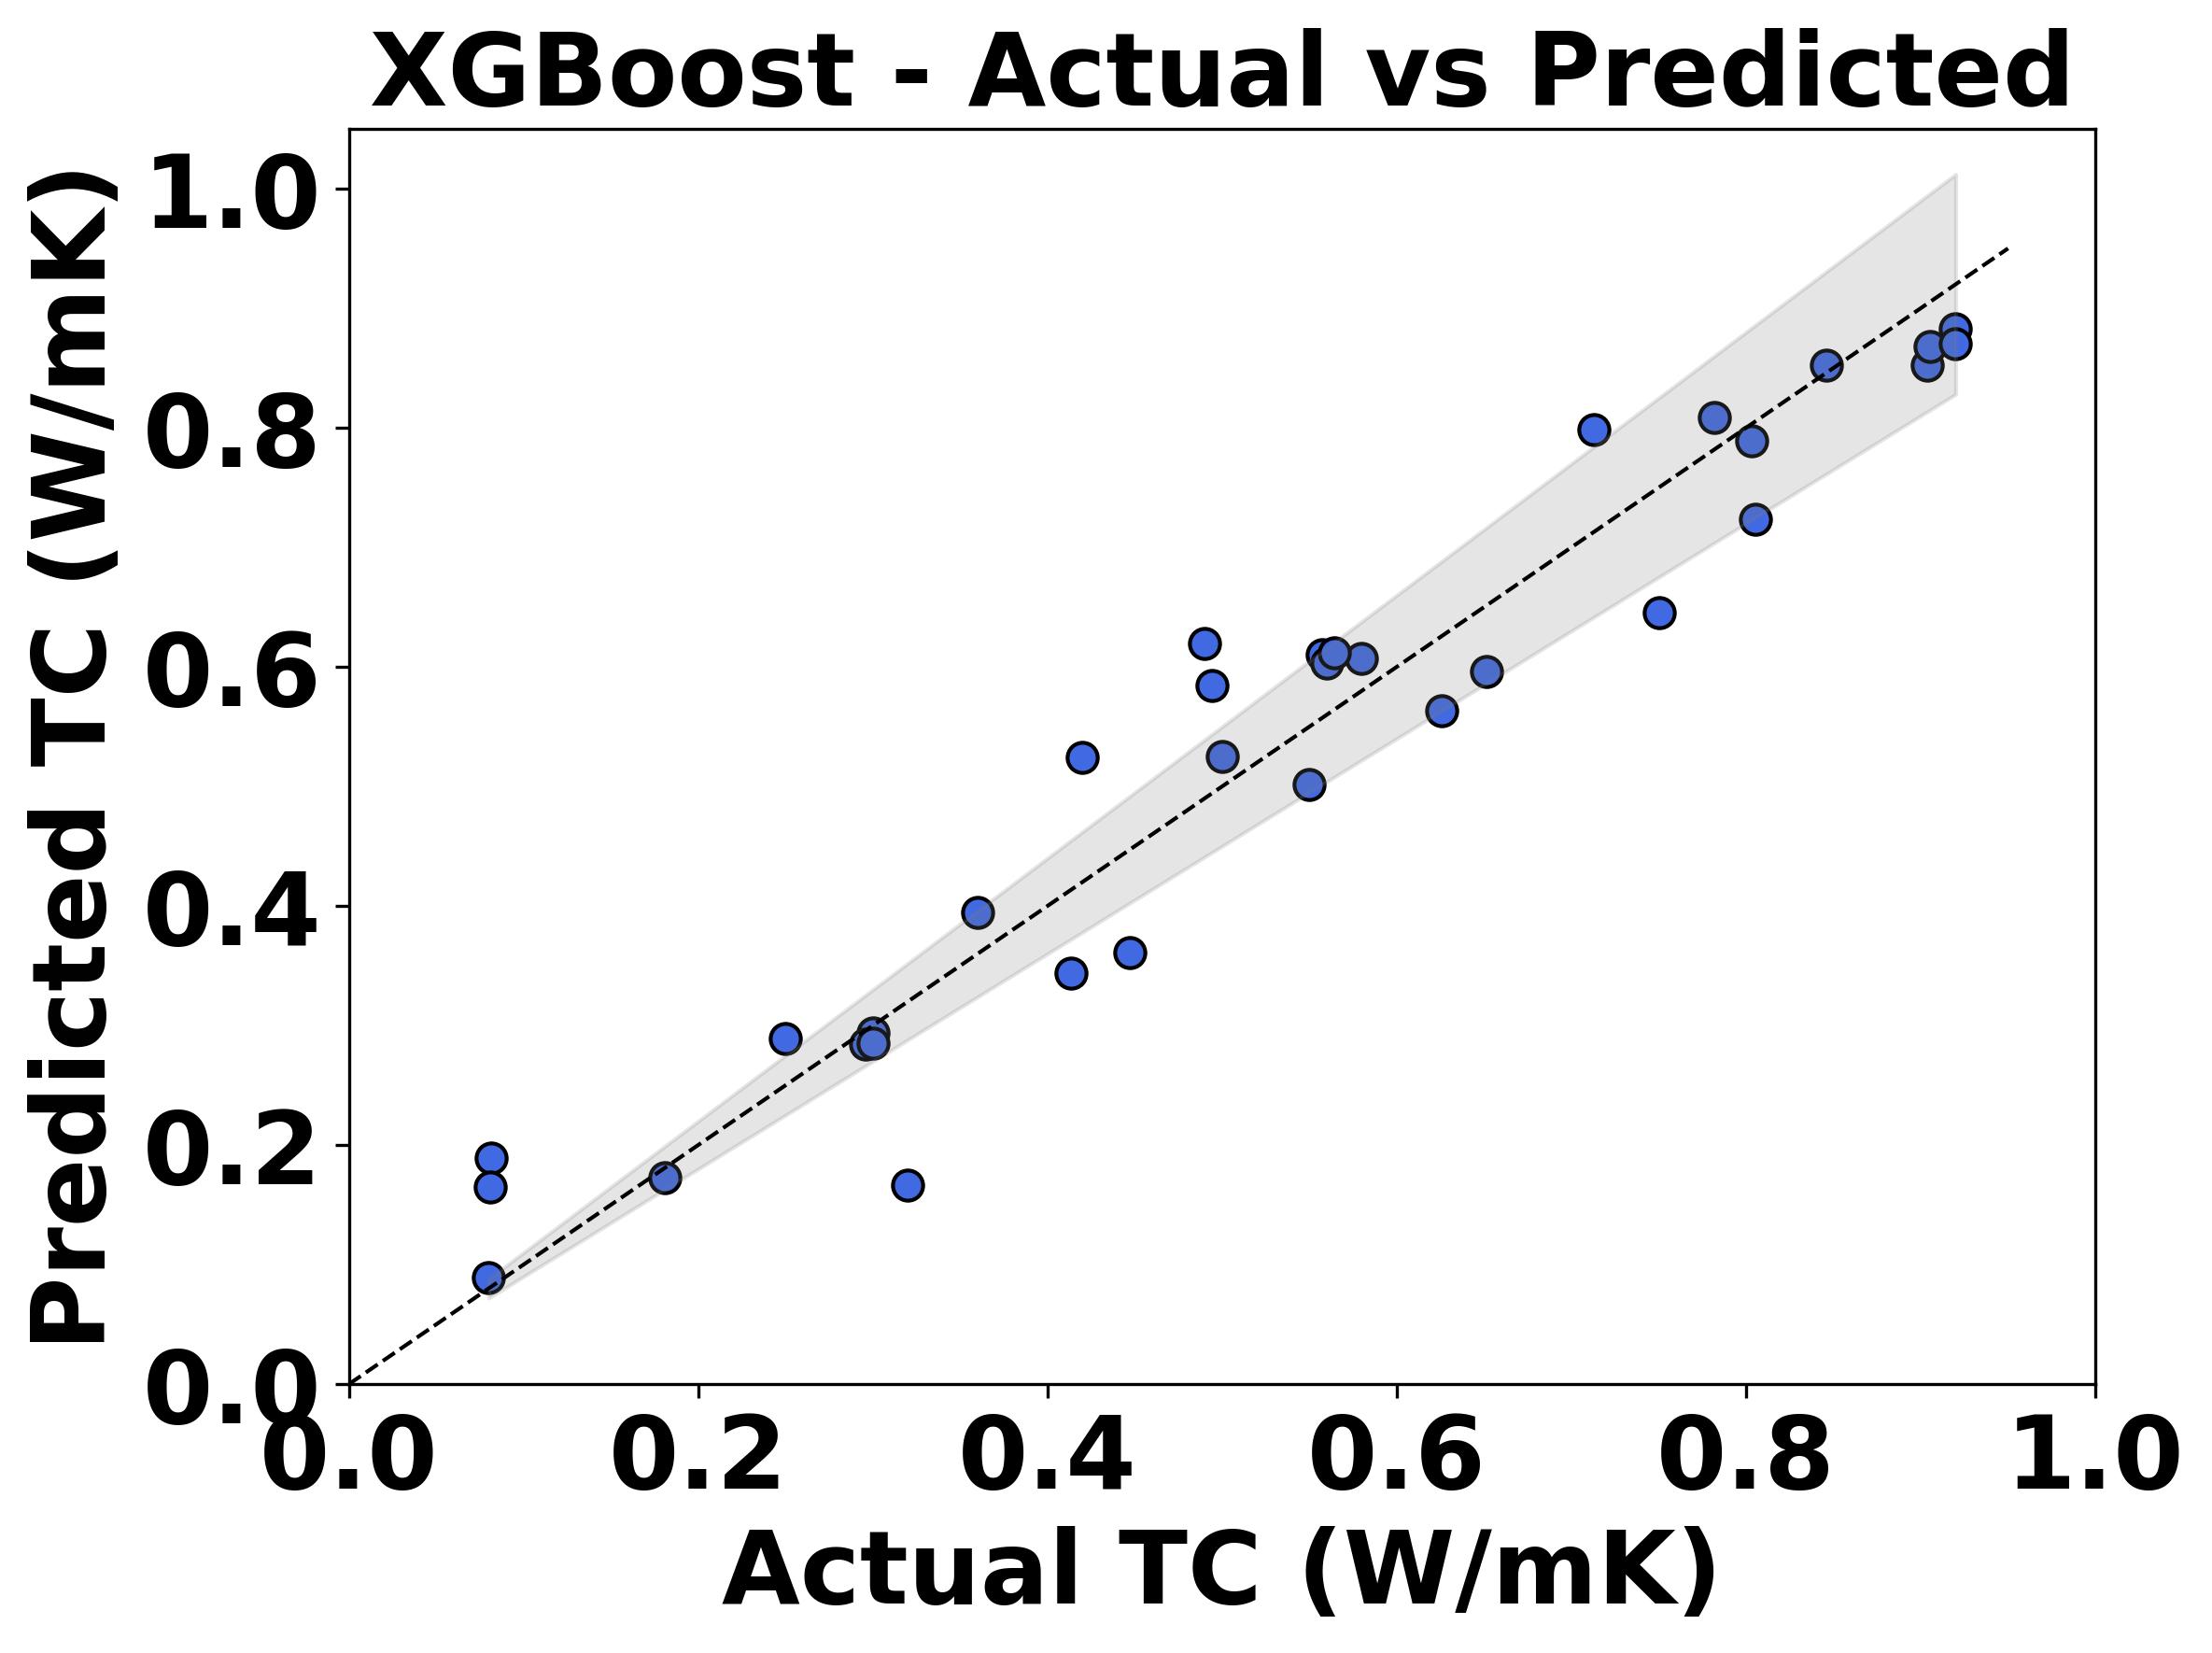

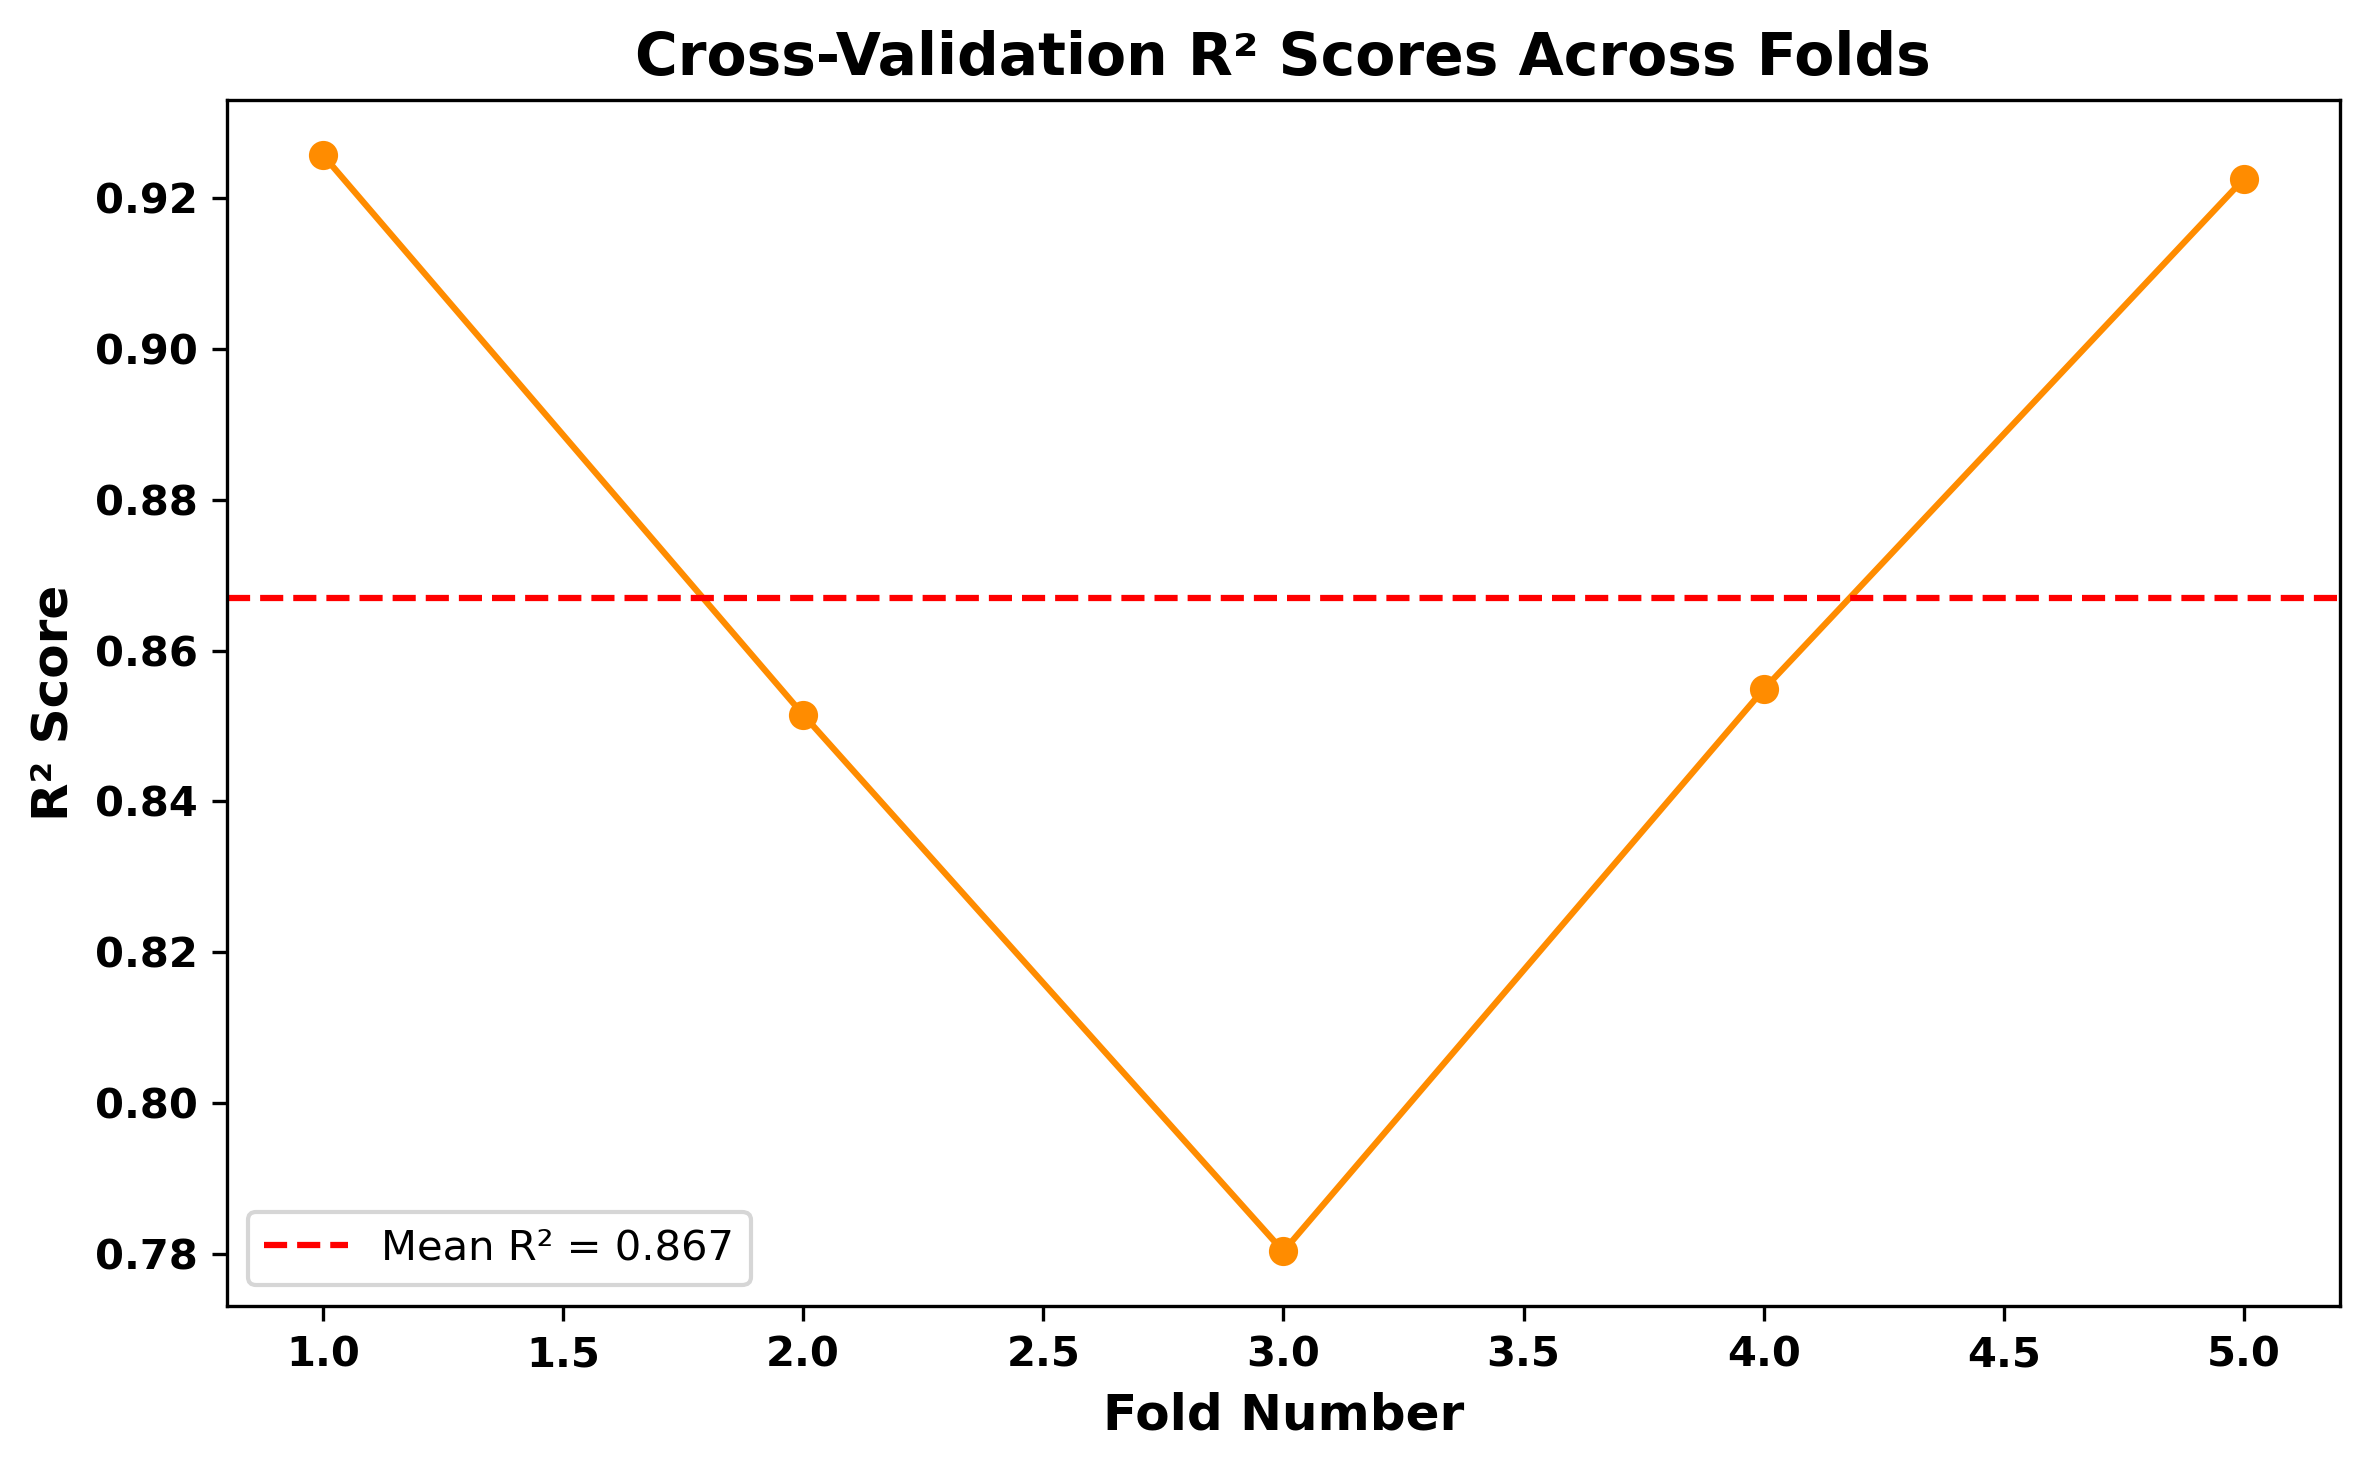

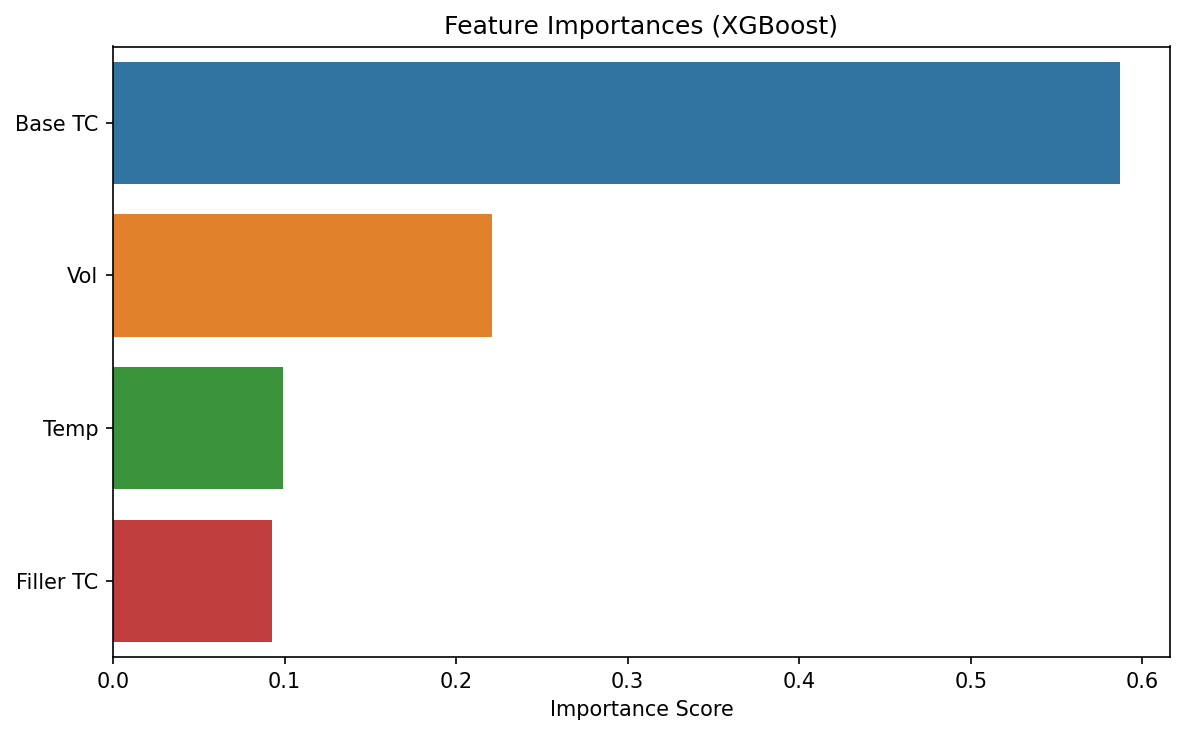

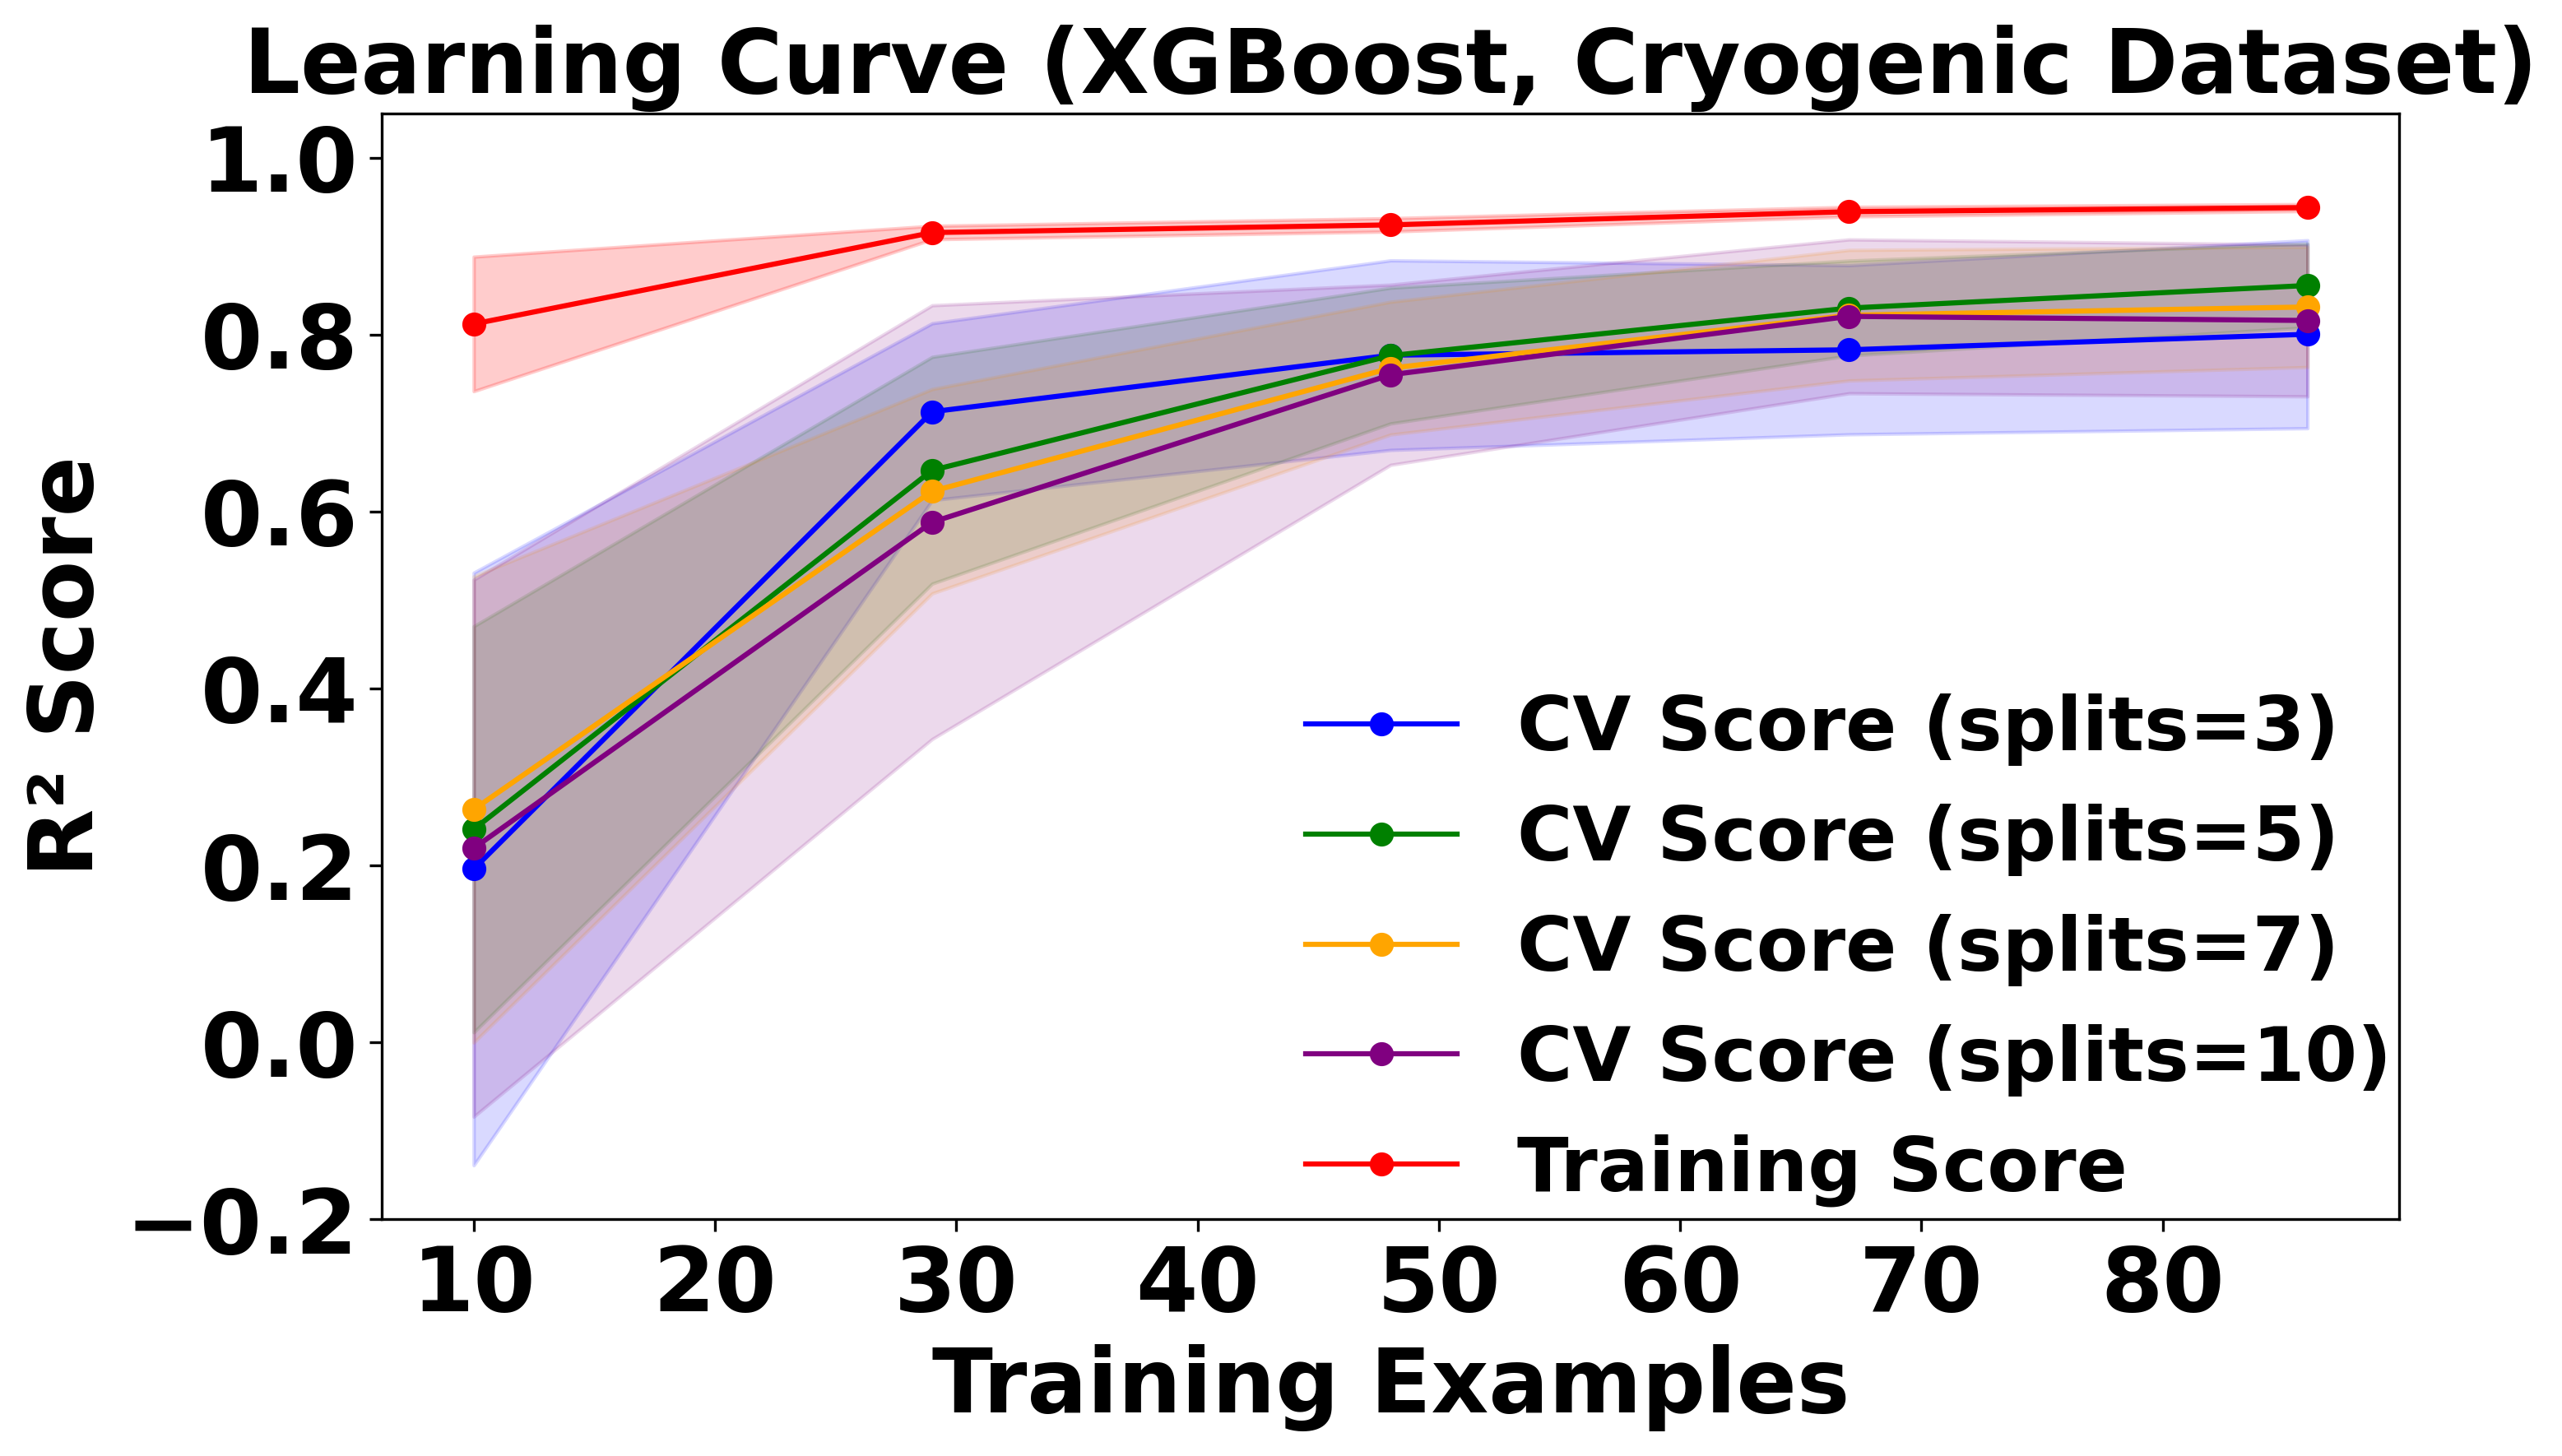

In [23]:
# 📦 Imports
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, KFold, learning_curve
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 📂 Load dataset
file_path = r'F:\Program Files (x86)\OneDrive\Desktop\ML edit 18\Cryogenic\Cryogenic_Temp_3x_Augmented_1Percent_Noise.xlsx'
df = pd.read_excel(file_path)

# 🧹 Features and Target
X = df.drop(columns=["Composite TC"])
y = df["Composite TC"]

# ✂️ Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ✅ Final XGBoost model with tuned hyperparameters
xgb_model = XGBRegressor(
    subsample=0.5,
    reg_lambda=5,
    reg_alpha=0.1,
    n_estimators=250,
    max_depth=3,
    learning_rate=0.03,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=0,
    n_jobs=-1
)

# 🚀 Train Model
start = time.time()
xgb_model.fit(X_train, y_train)
end = time.time()
print(f"\n⏱ Training Time: {end - start:.2f} seconds")

# 📈 Predictions
y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)

# 📊 Evaluation Function
def print_metrics(true, pred, dataset_name="Dataset"):
    print(f"\n{dataset_name} Metrics:")
    print(f"MAE:  {mean_absolute_error(true, pred):.4f}")
    print(f"RMSE: {mean_squared_error(true, pred, squared=False):.4f}")
    print(f"R²:   {r2_score(true, pred):.4f}")

# 🧾 Final Evaluation
print_metrics(y_train, y_train_pred, "Train")
print_metrics(y_test, y_test_pred, "Test")

# 🔁 5-Fold Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=cv, scoring='r2', n_jobs=-1)
print(f"\n📉 5-Fold Cross-Validation R² Scores: {np.round(cv_scores, 4)}")
print(f"Mean CV R²: {cv_scores.mean():.4f}")
print(f"Std Dev CV R²: {cv_scores.std():.4f}")

# 🔍 Full Test Data Output
test_combined = X_test.copy()
test_combined['Composite_Tc'] = y_test
print("\n🔍 Full Test Data (20% sample):\n", test_combined)

# 🔮 Manual prediction
manual_input = [[0.35, 0.65, 15, 4.2]]
predicted_tc = xgb_model.predict(manual_input)
print(f"\n🧪 Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")

# 🖼️ Scatter Plot with ±10% Band
y_true = y_test.values
y_pred = y_test_pred
lower = y_true * 0.90
upper = y_true * 1.10
sorted_idx = np.argsort(y_true)

plt.figure(figsize=(8, 6), dpi=300)
plt.scatter(y_true, y_pred, color='royalblue', s=60, edgecolor='black')
plt.fill_between(np.sort(y_true), lower[sorted_idx], upper[sorted_idx], color='gray', alpha=0.2)
plt.plot([0, 0.95], [0, 0.95], 'k--', lw=1)
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.xlabel('Actual TC (W/mK)', fontsize=26, fontweight='bold')
plt.ylabel('Predicted TC (W/mK)', fontsize=26, fontweight='bold')
plt.title('XGBoost - Actual vs Predicted', fontsize=26, fontweight='bold')
plt.locator_params(axis='x', nbins=6)
plt.locator_params(axis='y', nbins=6)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

# 📈 Line Plot of CV Scores
plt.figure(figsize=(8, 5), dpi=300)
plt.plot(range(1, len(cv_scores)+1), cv_scores, marker='o', linestyle='-', color='darkorange')
plt.axhline(y=cv_scores.mean(), color='red', linestyle='--', label=f'Mean R² = {cv_scores.mean():.3f}')
plt.title('Cross-Validation R² Scores Across Folds', fontsize=14, fontweight='bold')
plt.xlabel('Fold Number', fontsize=12, fontweight='bold')
plt.ylabel('R² Score', fontsize=12, fontweight='bold')
plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.grid(False)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

# 📊 Feature Importance
feat_imp = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5), dpi=150)
sns.barplot(x=feat_imp, y=feat_imp.index)
plt.title("Feature Importances (XGBoost)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

# 📚 Learning Curve
splits_list = [3, 5, 7, 10]
colors = ['blue', 'green', 'orange', 'purple']
min_allowed_size = min([int(len(X_train) * ((s - 1) / s)) for s in splits_list])
train_sizes_fixed = np.linspace(10, min_allowed_size, 5, dtype=int)

plt.figure(figsize=(10, 6), dpi=300)
for split, color in zip(splits_list, colors):
    train_sizes, train_scores, val_scores = learning_curve(
        xgb_model, X_train, y_train,
        train_sizes=train_sizes_fixed,
        cv=KFold(n_splits=split, shuffle=True, random_state=42),
        scoring='r2',
        n_jobs=-1
    )
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    plt.plot(train_sizes, val_mean, marker='o', label=f'CV Score (splits={split})', color=color)
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color=color, alpha=0.15)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
plt.plot(train_sizes, train_mean, marker='o', color='red', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='red', alpha=0.2)

plt.title('Learning Curve (XGBoost, Cryogenic Dataset)', fontsize=26, fontweight='bold')
plt.xlabel('Training Examples', fontsize=26, fontweight='bold')
plt.ylabel('R² Score', fontsize=26, fontweight='bold')
plt.legend(loc='lower right', bbox_to_anchor=(1.03, -0.05), prop={'weight': 'bold', 'size': 22}, frameon=False)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.ylim(-0.2, 1.05)
plt.grid(False)
plt.tight_layout()
plt.show()